## Commpare




In [1]:

import os
os.environ["JAX_ENABLE_X64"] = "True"

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_load
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_load import load, date, preprocess
r_nms = load("nms", start=date(2020,1,1), num_workers=4)
print(f"nms /done - found {len(r_nms.ts['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training 20-pca-fixed-SELU version 0.1 for 200000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using batches of 128 samples with learning rate 0.001 and weight decay 0.0001.
01:   Model config: 0.25-smooth@20@5qr midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True)
01:   Grid config: nms,rg=(-2,1),nm=20,xp=(2.0,4.9,9.9,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Preparing data set 20-pca-fixed-SELU version 0.1 for 0.25-smooth@20@5qr midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True) traing TrainConfig(num_epochs=200000, lr=0.001, weight_decay=0.0001, batch_size=128) on Env(prec=32,device=cuda,debug=False)... done; this took 0.29s.
00: Inst

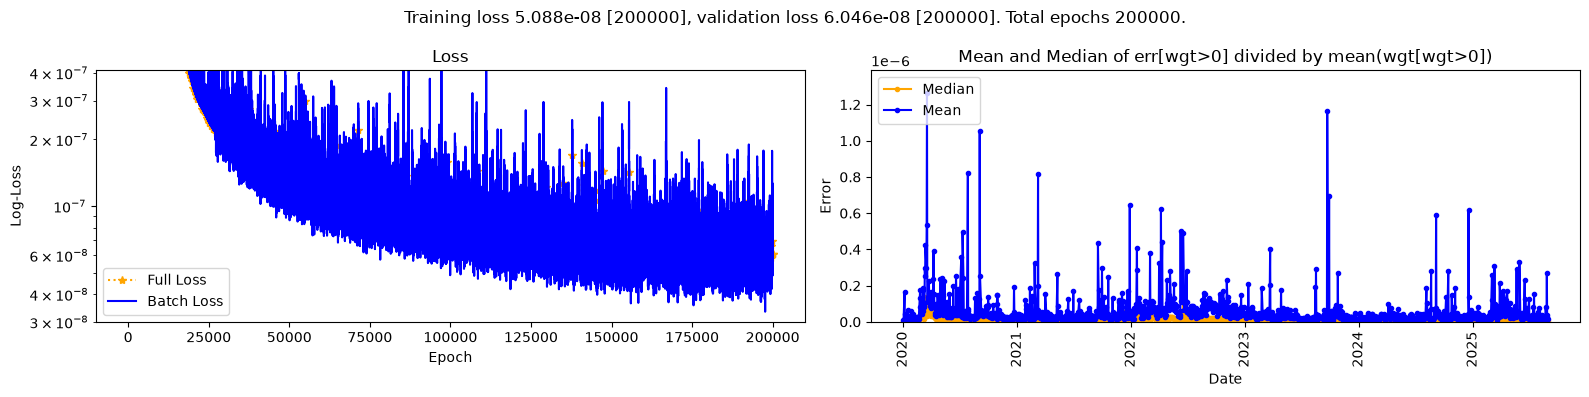

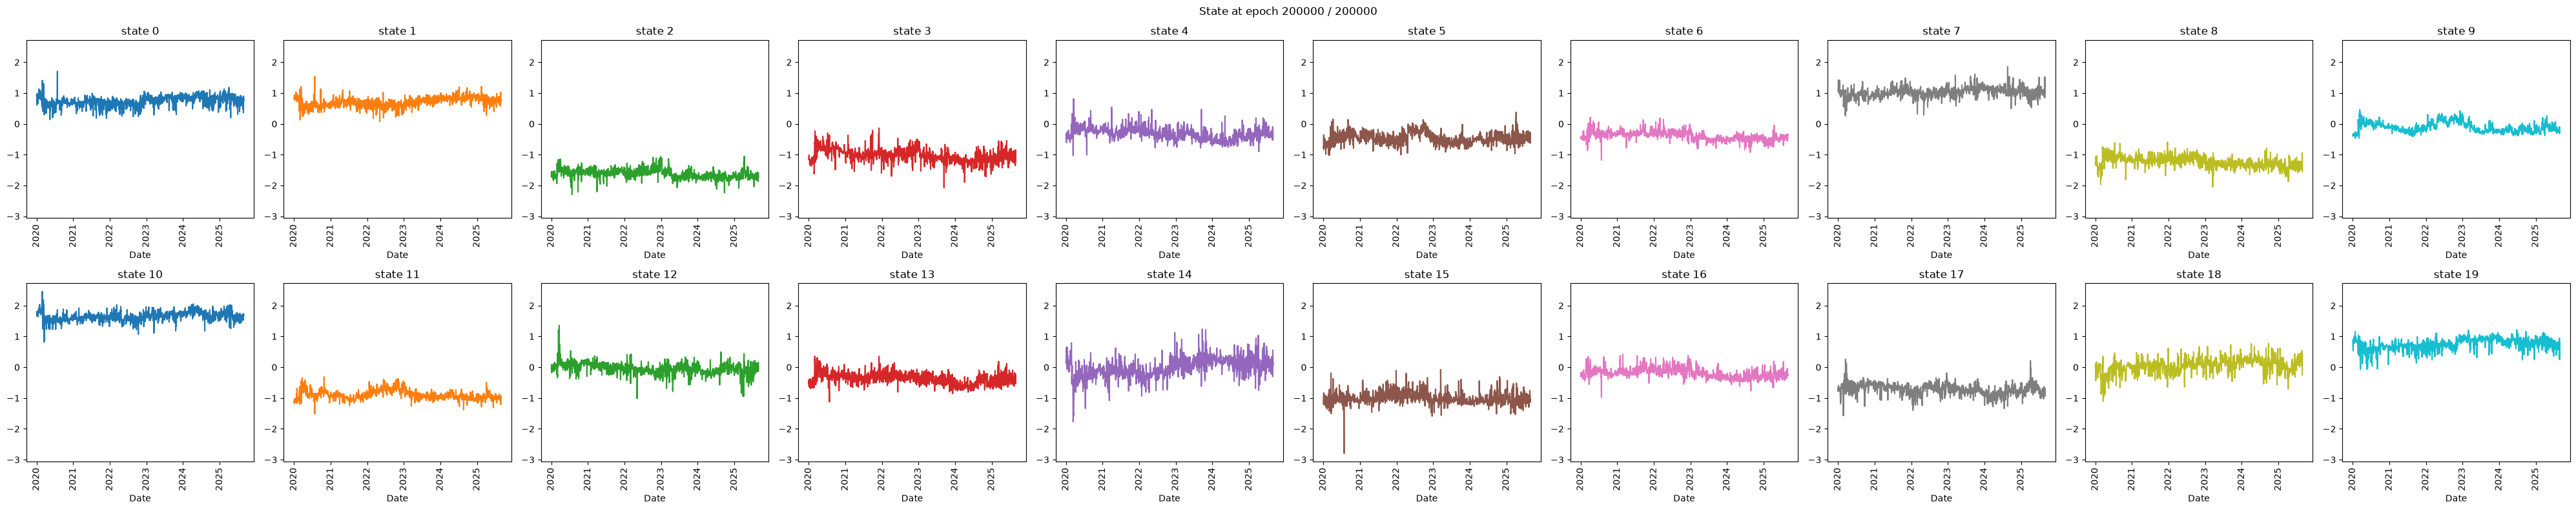

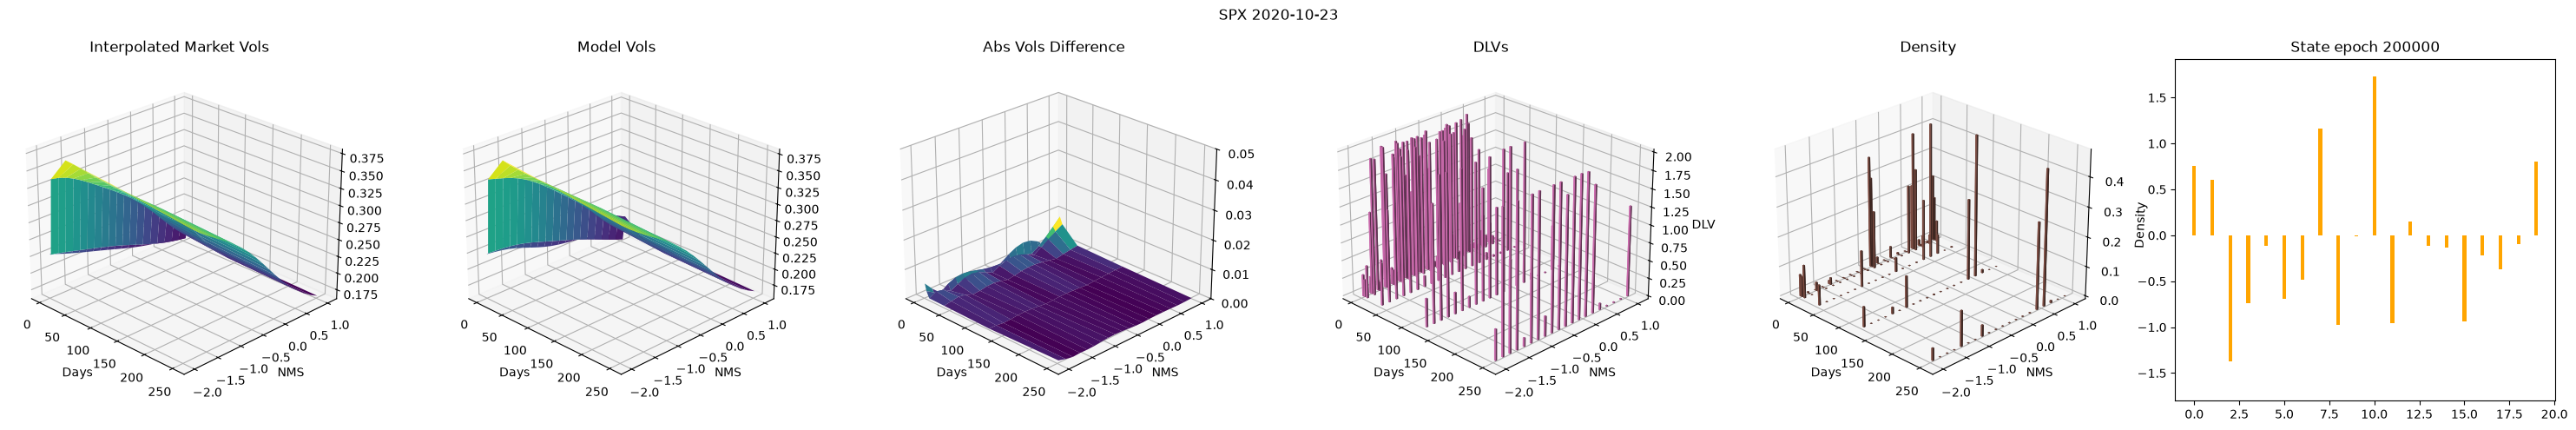

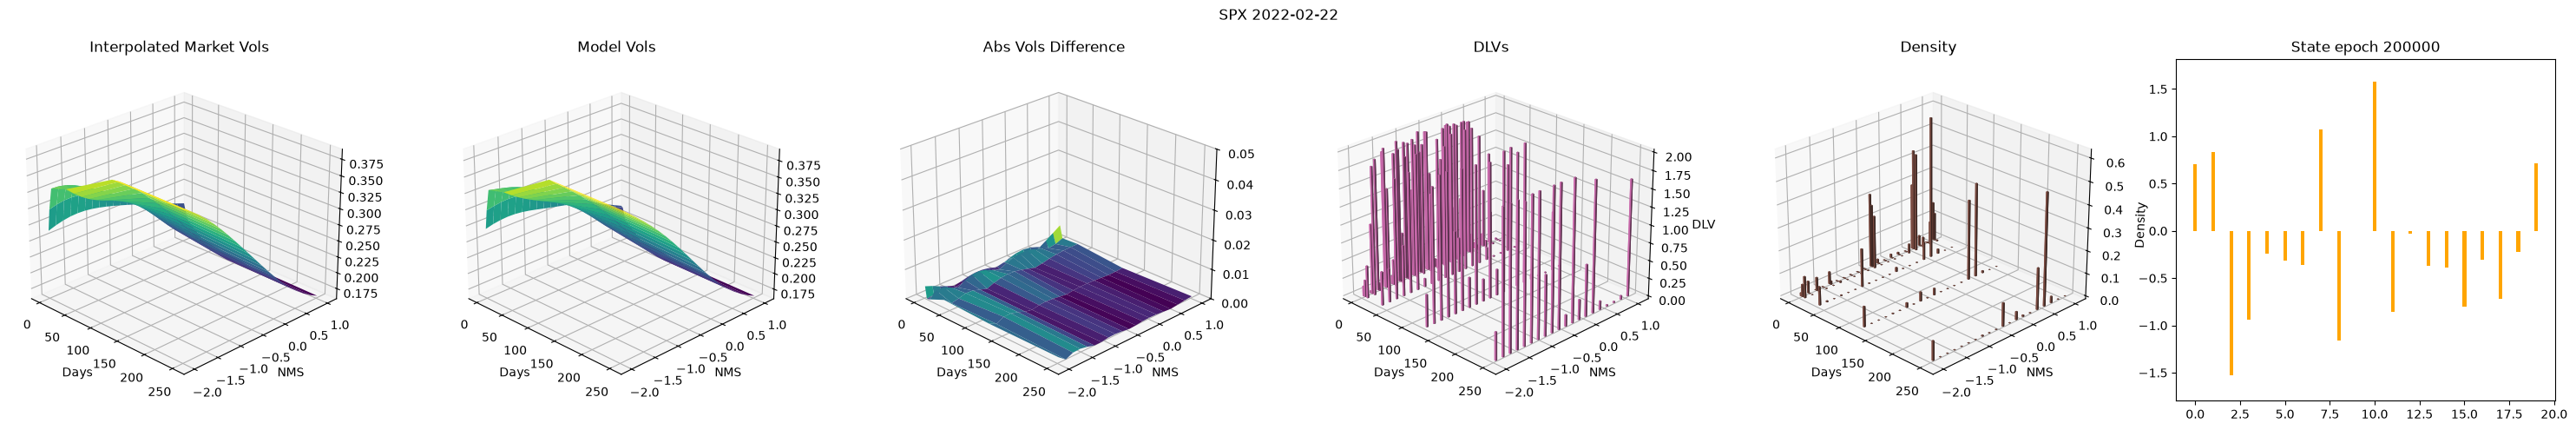

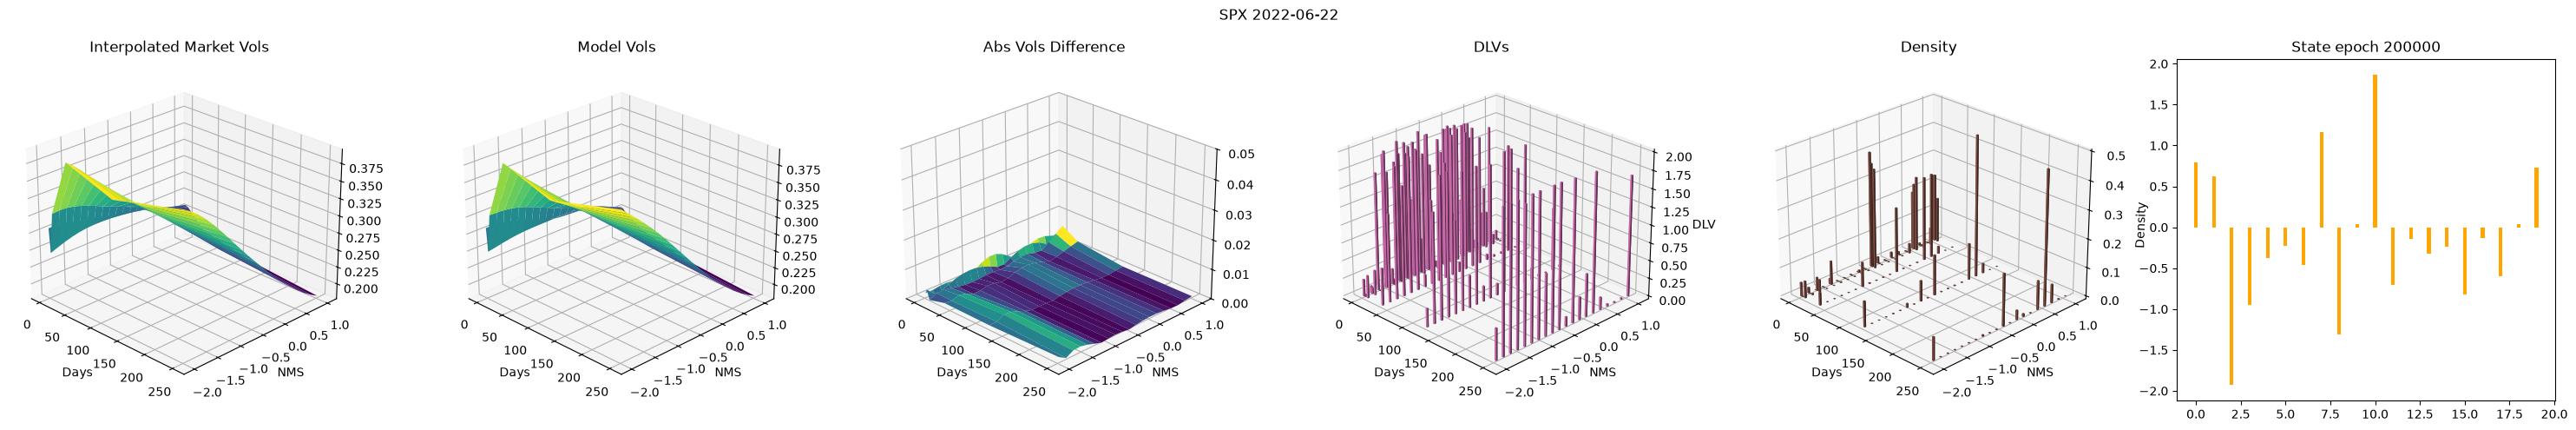

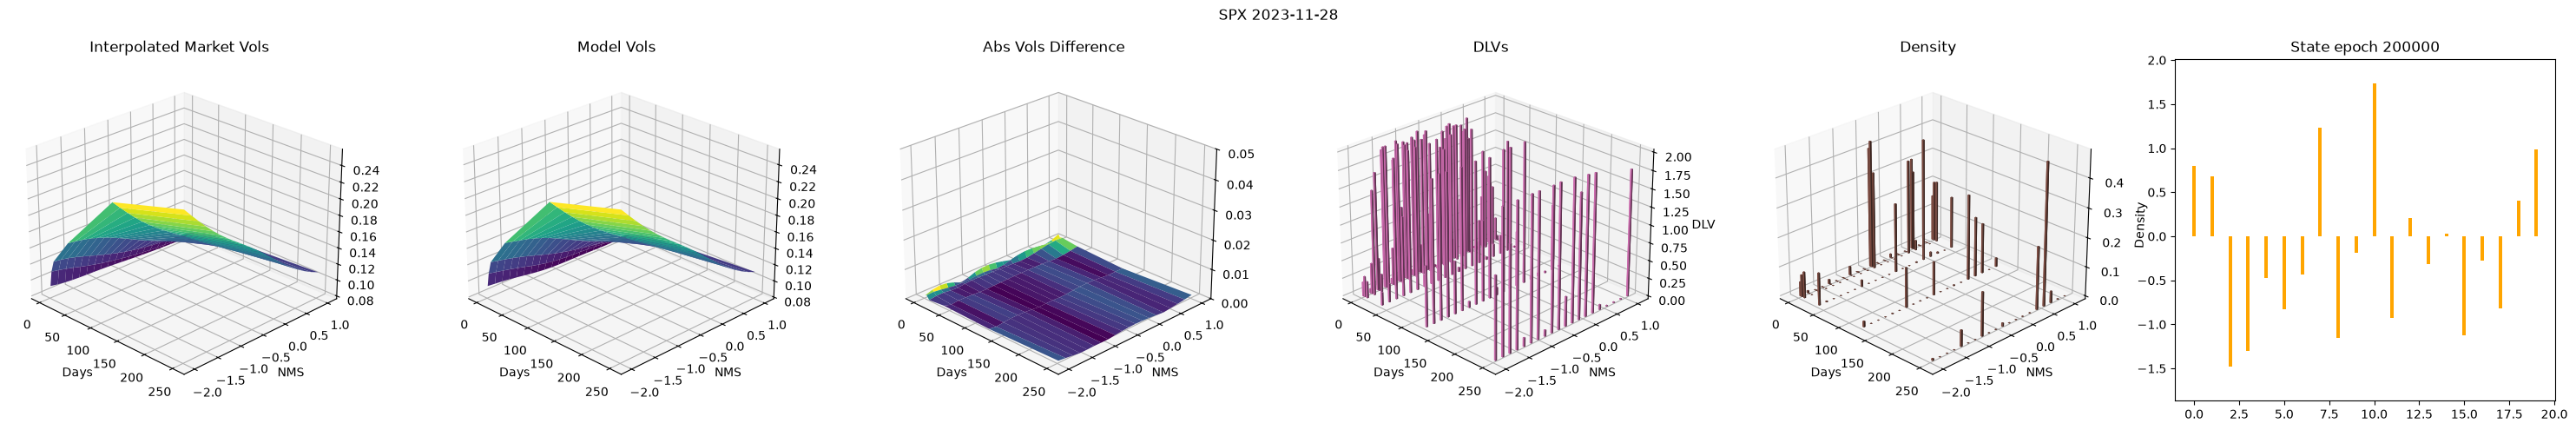

00: Training 0.25-smooth@20@5qr midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True) with TrainConfig(num_epochs=200000, lr=0.001, weight_decay=0.0001, batch_size=128) on Env(prec=32,device=cuda,debug=False):
01:   Epoch 27200/200000, Loss: 2.222e-07. So far this took 6s.   

/home/hans/vqdata/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


01:   Epoch 130930/200000, Loss: 7.464e-08. So far this took 1:18:20.                                               

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



00: Model trained for 200000 epochs. Final training loss: 5.088e-08, valuation loss: 6.046e-08. This took 2:11:24.  
/done


In [2]:
from cdxcore.bs import bs
from flax.nnx import state

from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.dysanos.grid.torch_model_pca import BaseEnvironment, SanosPCACompressorConfig, SanosPCACompressor, FeedForward, torch
from dataclasses import dataclass
import numpy as np
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.dysanos.grid.torch_gfx import Display
from quantdata.dysanos.grid.torch_train import train, TrainConfig

mdl_config = SanosPCACompressorConfig( 
    label="20-pca-fixed-SELU",
    user_version="0.1",
    smoothness = 0.25,
    num_state = 20, 
    num_pca = 5,
    use_qr = True,
    state_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    learn_config = None
)

trn_config = TrainConfig( num_epochs=200000, lr=1E-3, weight_decay=1e-4, batch_size=128 )
r = train( r_nms, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4, viz_store_epoch_interval=200 )
print("/done")
